# Study 1, notebook 1: the case

The 2D flux upper limit is computed for one mock case at a time. This notebook shows what the case
is: the GW event and its merger time, the pointings, the fields they are grouped into, and how much
of the GW probability the observations can see.

Inputs: `configs/cases/<CASE>.yaml`, the skymap it names, the cached tilepy tiling (`cache/tilepy_2d`,
tiling cases only) and the GW maps on the field geometries (`cache/gwmap`).

The only parameter is the case name, in the next cell.

In [1]:
CASE = "sim_wobble"   # case name in configs/cases/

Imports, and the figure saver of this notebook.

In [2]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy_healpix as ah
from astropy.coordinates import SkyCoord

from uuls import cases, fields as fl, gwmap as gwm
from uuls.figures import FigureSaver, COLORS

figs = FigureSaver("1_flux_ul", "1_case")

Two small helpers for sky plots: centres of the multi-order HEALPix pixels, and RA unwrapped around a reference.

In [3]:
def pixel_coords(sky, sel):
    """Centres (ra, dec in deg) of the HEALPix pixels `sel` of a multi-order skymap."""
    level, ipix = ah.uniq_to_level_ipix(sky.uniq[sel])
    lon, lat = ah.healpix_to_lonlat(ipix, nside=ah.level_to_nside(level), order="nested")
    return lon.to_value(u.deg), lat.to_value(u.deg)


def wrap(ra, ra0):
    """RA unwrapped around ra0, so that a region across RA = 0 plots in one piece."""
    return (np.asarray(ra) - ra0 + 180.0) % 360.0 - 180.0 + ra0

## Case configuration

The case fixes the GW event, the rule for the merger time (simulated cases move it to the first dark
night with the skymap peak below 40 deg zenith; the skymap itself is not rotated), the data source and
the pointing strategy.

In [4]:
case = cases.load_case(CASE)
print(case.summary())
t0 = case.t0()
target = case.target()
print(f"t0 = {t0.isot} UTC, target (skymap peak) RA {target.ra.deg:.3f}, Dec {target.dec.deg:.3f} deg")
print("reduce overrides:", case.analysis.get("reduce"))

{'name': 'sim_wobble', 'skymap': 'S240615dg.fits', 'pe': 'S240615dg', 't0': 'observable after 2026-01-01T12:00:00.000', 'data': 'simulst (nsb 0.14, seed 1)', 'strategy': 'wobble'}


t0 = 2026-01-01T19:49:52.383 UTC, target (skymap peak) RA 8.008, Dec 45.784 deg
reduce overrides: {'background': 'fov'}


The pointings: one row per run, start times in seconds after the merger.

In [5]:
pointings = case.pointings()
tab = pointings.copy()
tab["t_start_s"] = np.round((tab["t_start"] - t0).to_value(u.s), 0)
cols = [c for c in ("obs_id", "ra", "dec", "t_start_s", "duration", "wobble_angle", "pgw") if c in tab.colnames]
tab[cols].pprint(max_lines=30, max_width=120)
print(f"{len(tab)} runs, {tab['duration'].sum() / 3600:.2f} h in total, last run ends "
      f"{(tab['t_start_s'][-1] + tab['duration'][-1]) / 3600:.2f} h after t0")

obs_id         ra               dec        t_start_s duration wobble_angle
              deg               deg                     s                 
------ ----------------- ----------------- --------- -------- ------------
     1 8.008474576271189 46.18396716177501      60.0   1200.0          0.0
     2 8.582051889253618 45.78253218054236    1260.0   1200.0         90.0
     3 8.008474576271189 45.38396716177502    2460.0   1200.0        180.0
     4 7.434897263288757 45.78253218054236    3660.0   1200.0        270.0
4 runs, 1.33 h in total, last run ends 1.35 h after t0


## GW skymap

Greedy credible areas of the skymap. The upper limit is for a source inside the 95% region (and
inside the observed part of it, see below).

In [6]:
sky = gwm.read_healpix(case.skymap)
levels = gwm.credible_levels(sky)
for cl in (0.5, 0.9, 0.95):
    print(f"{int(cl * 100)}% credible area: {gwm.credible_area_deg2(case.skymap, cl):8.1f} deg2")
in95 = levels <= 0.95
ra95, dec95 = pixel_coords(sky, in95)
print(f"{in95.sum()} HEALPix pixels in the 95% region, holding probability {sky.prob[in95].sum():.4f}")

50% credible area:      1.5 deg2
90% credible area:      5.1 deg2
95% credible area:      6.6 deg2
6633 HEALPix pixels in the 95% region, holding probability 0.9500


## Fields

Pointings closer than `analysis.fields.link_deg` share a field; each field gets its own small WCS
geometry, wide enough to hold every run out to the reduction's offset-max (2.5 deg), and its own GW
map on that geometry. Here only the geometries and GW maps are built (no data).

In [7]:
flds = fl.build_fields(case)
for f in flds:
    ny, nx = f.geom.to_image().data_shape
    print(f"{f.name}: runs {f.obs_ids}, centre RA {f.center.ra.deg:.2f} Dec {f.center.dec.deg:.2f}, "
          f"{nx} x {ny} bins, GW prob in its 95% mask {f.gwmap.prob[f.gwmap.mask].sum():.4f}")

[cache] gwmap/7a469d1cf166: loaded
field0: runs [1, 2, 3, 4], centre RA 8.01 Dec 45.78, 73 x 73 bins, GW prob in its 95% mask 0.9486


The 95% region on the sky (pixel centres coloured by probability density), the pointings with a
circle at the offset-max (out to which events are kept) and the footprint of each field geometry
(dashed).

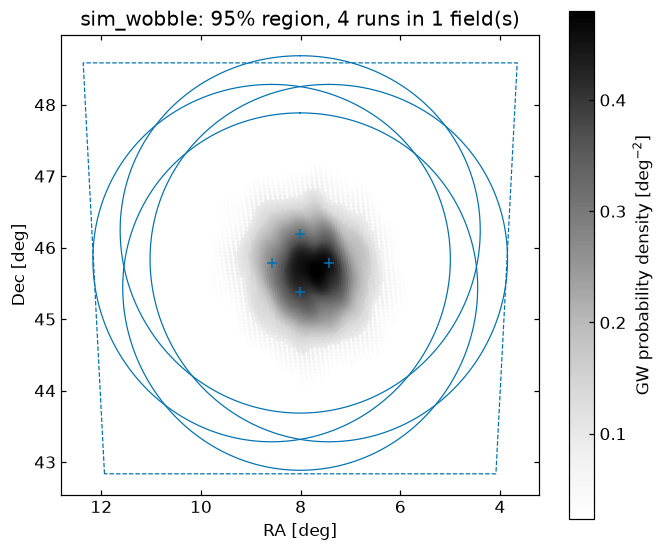

In [8]:
ra0 = target.ra.deg
dens = (sky.prob / sky.area_sr)[in95] * (np.pi / 180) ** 2      # deg-2
r = flds[0].info["offset_max_deg"]
phi = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(wrap(ra95, ra0), dec95, c=dens, s=2, cmap="Greys", rasterized=True)
fig.colorbar(sc, ax=ax, label="GW probability density [deg$^{-2}$]")
for k, f in enumerate(flds):
    col = COLORS[k % len(COLORS)]
    corners = f.geom.to_image().wcs.calc_footprint()
    corners = np.vstack([corners, corners[:1]])
    ax.plot(wrap(corners[:, 0], ra0), corners[:, 1], color=col, lw=0.8, ls="--")
    for row in f.pointings:
        c = SkyCoord(row["ra"], row["dec"], unit="deg").directional_offset_by(phi * u.rad, r * u.deg)
        ax.plot(wrap(c.ra.deg, ra0), c.dec.deg, color=col, lw=0.8)
        ax.plot(wrap(row["ra"], ra0), row["dec"], "+", color=col, ms=6)
ax.invert_xaxis()
ax.set_aspect(1 / np.cos(np.deg2rad(target.dec.deg)))
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title(f"{case.name}: 95% region, {len(pointings)} runs in {len(flds)} field(s)")
figs.save(fig, "sky")
plt.show()

The GW probability per bin on the geometry of the field holding most of it, with the 95% mask and
the pointings of that field.

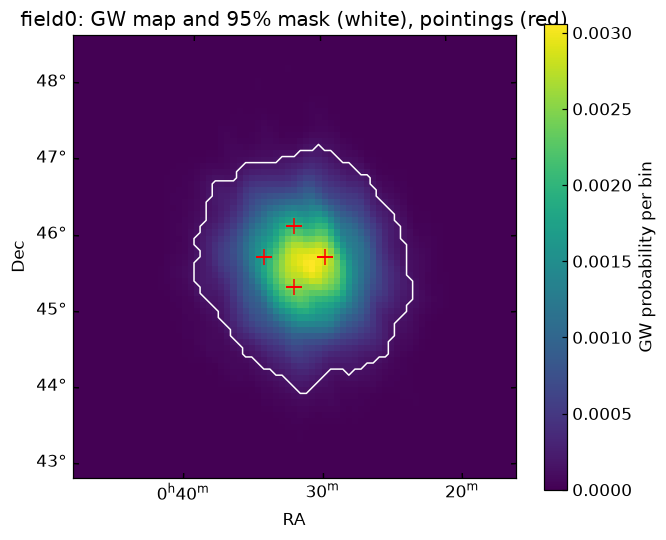

In [9]:
k = int(np.argmax([f.gwmap.prob[f.gwmap.mask].sum() for f in flds]))
f = flds[k]
image = f.geom.to_image()
fig = plt.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(projection=image.wcs)
im = ax.imshow(f.gwmap.prob, origin="lower", cmap="viridis")
ax.contour(f.gwmap.mask.astype(float), levels=[0.5], colors="w", linewidths=1)
pix = image.coord_to_pix(SkyCoord(f.pointings["ra"], f.pointings["dec"], unit="deg"))
ax.plot(pix[0], pix[1], "r+", ms=10)
fig.colorbar(im, ax=ax, label="GW probability per bin")
ax.set_xlabel("RA")
ax.set_ylabel("Dec")
ax.set_title(f"{f.name}: GW map and 95% mask (white), pointings (red)")
figs.save(fig, "gw_on_field")
plt.show()

## Coverage of the GW probability

A pixel of the 95% region can only be observed if it lies within the offset-max of some run. The
curve is the GW probability within a distance r of the nearest pointing; the vertical line is the
offset-max used by the reduction. The exact region of interest (exposure > 0 inside the safe mask,
intersected with the 95% mask) comes from the reduced data, in notebook 2; it agrees with this
geometric estimate up to the bin size.

GW probability within 2.5 deg of a pointing: 0.9500 (100.0% of the 95% region)


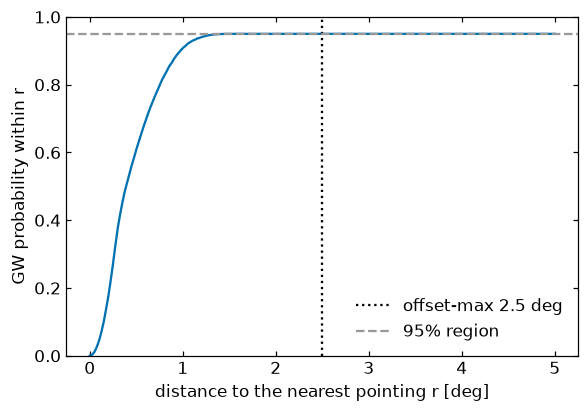

In [10]:
pts = SkyCoord(pointings["ra"], pointings["dec"], unit="deg")
pix95 = SkyCoord(ra95, dec95, unit="deg")
dmin = np.min([pix95.separation(p).deg for p in pts], axis=0)
p95 = sky.prob[in95]
rr = np.linspace(0, max(5.0, 1.2 * r), 200)
covered = np.array([p95[dmin <= x].sum() for x in rr])
p_cov = p95[dmin <= r].sum()
print(f"GW probability within {r} deg of a pointing: {p_cov:.4f} "
      f"({p_cov / p95.sum():.1%} of the 95% region)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rr, covered)
ax.axvline(r, color="k", ls=":", label=f"offset-max {r} deg")
ax.axhline(p95.sum(), color="0.6", ls="--", label="95% region")
ax.set_xlabel("distance to the nearest pointing r [deg]")
ax.set_ylabel("GW probability within r")
ax.set_ylim(0, 1)
ax.legend()
figs.save(fig, "coverage")
plt.show()

## Outputs

Figures in `outputs/figures/1_flux_ul/1_case/`: `sky`, `gw_on_field`, `coverage`. Nothing else is
written; the GW maps on the field geometries are in the cache (`cache/gwmap`).